# 2K — Cognate-substrate value vs on-target transporter effect

The all-pairs analyses are dominated by promiscuous off-target effects. Here we restrict each
transporter to its **annotated (cognate) substrate(s)** and ask whether the *on-target* effect
of deleting the transporter relates to the substrate's metabolite value.

Substrate→metabolite mapping is curated from the `Transported metabolites` annotation
(`B_selected_transporters...csv`), keeping only substrates present in the measured metabolome.
Direction convention: for an **importer**, a positive on-target effect (KO raises release) means
the transporter normally re-imports / salvages its own substrate.

In [1]:
import pandas as pd, numpy as np, scipy.stats as st
import matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
repo_folder=Path('../../..')
data_folder=repo_folder/'data'/'this_project'/'6_transporterKO'
mfolder=data_folder/'D_big_screen'; figure_folder=repo_folder/'figures'/'3_big_screen'
norm='TIC'; lam=10; xval='AUC OD'; max_pval=0.005; min_effect=3

In [2]:
df_ionMz=pd.read_csv(mfolder/'H_ionMz_annotation.csv').drop_duplicates(subset=['ionMz'])
dis_df=pd.read_csv(mfolder/f'K_timecurve_comparison_{norm}_norm_lam_{lam}_{xval}.csv',index_col=0)
dis_mz=dis_df.merge(df_ionMz,on='ionMz',how='left')
dis_mz=dis_mz[~dis_mz.Strain.isin(['dppB','tolC','ptsG'])]

dfv=pd.read_csv(data_folder/'Z_div/I_metabolite_values_big_screen.csv')
dfv['logv']=np.log10(dfv['Metabolite value'])
k2lv=dfv.set_index('kegg_id')['logv'].to_dict()
def met_lv(k):
    if pd.isna(k): return np.nan
    vals=[k2lv.get(x,np.nan) for x in k.split(';')]
    return np.nan if all(pd.isna(vals)) else np.nanmean(vals)
ann=df_ionMz.drop_duplicates('Metabolite')[['Metabolite','KEGG','Classification']].copy()
ann['logv']=ann['KEGG'].apply(met_lv)
met2lv=ann.set_index('Metabolite')['logv'].to_dict()
tm=pd.read_csv(data_folder/'B_selected_transporters_with_expression_levels.csv')
s2dir=tm.set_index('Gene Name')['Expected direction'].to_dict()

## Curated cognate substrate map (verified against measured metabolome)

In [3]:
cognate={
 'cstA':['Pyruvate'],'glpT':['sn-Glycerol 3-phosphate'],'ugpA':['sn-Glycerol 3-phosphate'],
 'actP':['Acetatic acid','Glycolate'],'gltS':['Glutamate'],
 'dctA':['Malate','Aspartate','Orotate','Fumarate','Succinate'],
 'livH':['(Iso)Leucine','Valine','Phenylalanine','Threonine'],
 'mtr':['Tryptophan'],'tdcC':['Threonine','Serine'],
 'nupG':['Cytidine','Uridine','Thymidine','Guanosine'],'nupC':['Cytidine','Uridine','Thymidine'],
 'argO':['Arginine'],'artQ':['Arginine'],'ygaZ':['Valine'],'kgtP':['Oxoglutarate'],
 'hisQ':['Lysine','Arginine','Ornithine','Histidine'],'aroP':['Phenylalanine','Tyrosine','Tryptophan'],
 'metI':['Methionine'],'pheP':['Phenylalanine'],'gltJ':['Glutamate','Aspartate'],
 'glnP':['Glutamine'],'rhtA':['Threonine'],'yeaS':['(Iso)Leucine','Methionine'],
 'yedA':['Phenylalanine','Threonine'],'lysP':['Lysine'],'sdaC':['Serine'],
 'proP':['Proline'],'cycA':['Alanine','Serine','Glycine'],'ansP':['Asparagine'],
 'rhtB':['Homoserine lactone','Threonine'],'rhtC':['Threonine'],'ybjE':['Lysine'],
 'codB':['Cytosine'],'brnQ':['Valine','(Iso)Leucine'],'eamA':['Cys','Glutamine','Asparagine'],
 'nagE':['N-Acetyl-D-glucosamine'],'glpF':['Glycerol','Glycine'],'putP':['Proline'],
 'gadC':['Glutamate','Aminobutanoic acid (ABA)'],'sstT':['Serine','Threonine'],
 'dcuA':['Aspartate','Fumarate','Succinate','Malate'],'gltP':['Aspartate','Glutamate'],
 'satP':['Acetatic acid','Succinate'],'punC':['Guanine','Hypoxanthine','Xanthine'],
}
pairs=[(s,m) for s,ms in cognate.items() for m in ms]
cp=pd.DataFrame(pairs,columns=['Strain','Metabolite'])
eff=dis_mz.set_index(['Strain','Metabolite'])[['Rel. distance','p-value rel']]
cp=cp.merge(eff,on=['Strain','Metabolite'],how='left')
cp['logv']=cp['Metabolite'].map(met2lv)
cp['dir']=cp['Strain'].map(s2dir)
cp['|eff|']=cp['Rel. distance'].abs()
cp['sig']=(cp['|eff|']>min_effect)&(cp['p-value rel']<max_pval)
cp=cp.dropna(subset=['Rel. distance'])
print(f'cognate pairs with a measured effect: {len(cp)}  | significant: {cp.sig.sum()}  | transporters: {cp.Strain.nunique()}')
cp.head()

cognate pairs with a measured effect: 80  | significant: 10  | transporters: 43


,Strain,Metabolite,Rel. distance,p-value rel,logv,dir,|eff|,sig
0,cstA,Pyruvate,-0.436026,0.191,-1.493989,Import,0.436026,False
1,glpT,sn-Glycerol 3-phosphate,-0.435729,0.126,-1.450224,Import,0.435729,False
2,glpT,sn-Glycerol 3-phosphate,-0.792516,0.074,-1.450224,Import,0.792516,False
3,ugpA,sn-Glycerol 3-phosphate,1.080177,0.006,-1.450224,Import,1.080177,False
4,actP,Acetatic acid,2.376536,0.000,-2.005533,Import,2.376536,False


## On-target effect vs substrate value

In [4]:
def sp(x,y):
    s=pd.DataFrame({'x':x,'y':y}).dropna()
    if len(s)<5: return dict(r=np.nan,p=np.nan,n=len(s))
    r,p=st.spearmanr(s.x,s.y); return dict(r=round(r,3),p=float(f'{p:.3g}'),n=len(s))

print('signed on-target effect vs value :', sp(cp.logv,cp['Rel. distance']))
print('|on-target effect|   vs value    :', sp(cp.logv,cp['|eff|']))
print('significant only, signed vs value:', sp(cp[cp.sig].logv,cp[cp.sig]['Rel. distance']))
print()
for dn,g in cp.groupby('dir'):
    print(f'{dn:7s} signed vs value:', sp(g.logv,g['Rel. distance']))

# importer salvage: fraction of significant importer on-target effects that are positive, high vs low value
imp=cp[(cp.dir=='Import')&cp.sig].copy()
imp['pos']=imp['Rel. distance']>0
if len(imp)>=8:
    med=imp.logv.median()
    hi=imp[imp.logv>med].pos.mean(); lo=imp[imp.logv<=med].pos.mean()
    print(f'\nimporter sig on-target: frac positive (salvage)  low-value={lo:.2f}  high-value={hi:.2f}  (n={len(imp)})')

# per-transporter aggregate (reduces pseudoreplication)
agg=cp.groupby('Strain').agg(mean_signed=('Rel. distance','mean'),mean_abs=('|eff|','mean'),
                             mean_logv=('logv','mean'),dir=('dir','first')).reset_index()
print('\nPER-TRANSPORTER (mean over its substrates):')
print('  mean signed effect vs mean substrate value:', sp(agg.mean_logv,agg.mean_signed))
print('  mean |effect|      vs mean substrate value:', sp(agg.mean_logv,agg.mean_abs))

# sanity: on-target vs off-target |effect|
on=set(map(tuple,pairs))
dis_mz['ontarget']=[ (s,m) in on for s,m in zip(dis_mz.Strain,dis_mz.Metabolite)]
print('\nSANITY on- vs off-target median |effect|:',
      round(dis_mz.loc[dis_mz.ontarget,'Rel. distance'].abs().median(),2),'vs',
      round(dis_mz.loc[~dis_mz.ontarget,'Rel. distance'].abs().median(),2),
      '| Mann-Whitney P=%.2g'%st.mannwhitneyu(dis_mz.loc[dis_mz.ontarget,'Rel. distance'].abs(),
                                               dis_mz.loc[~dis_mz.ontarget,'Rel. distance'].abs())[1])

signed on-target effect vs value : {'r': np.float64(-0.013), 'p': 0.906, 'n': 80}
|on-target effect|   vs value    : {'r': np.float64(-0.13), 'p': 0.251, 'n': 80}
significant only, signed vs value: {'r': np.float64(-0.738), 'p': 0.0149, 'n': 10}

Both    signed vs value: {'r': np.float64(0.736), 'p': 0.0153, 'n': 10}
Export  signed vs value: {'r': np.float64(0.213), 'p': 0.447, 'n': 15}
Import  signed vs value: {'r': np.float64(-0.027), 'p': 0.846, 'n': 55}

importer sig on-target: frac positive (salvage)  low-value=1.00  high-value=0.75  (n=9)

PER-TRANSPORTER (mean over its substrates):
  mean signed effect vs mean substrate value: {'r': np.float64(0.026), 'p': 0.867, 'n': 43}
  mean |effect|      vs mean substrate value: {'r': np.float64(-0.032), 'p': 0.841, 'n': 43}

SANITY on- vs off-target median |effect|: 0.94 vs 0.55 | Mann-Whitney P=9.8e-06


## Figure

/var/folders/xf/kl76knj11y72v0_qy4vv7tgh0000gp/T/ipykernel_7196/4118877873.py:39: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=d,x='group',y='|effect|',ax=ax,cut=0,inner='quartile',palette=['#4c72b0','#c0c0c0'])


saved ../../../figures/3_big_screen/figure_5_cognate_substrate_value_vs_effect_TIC_norm_lam_10


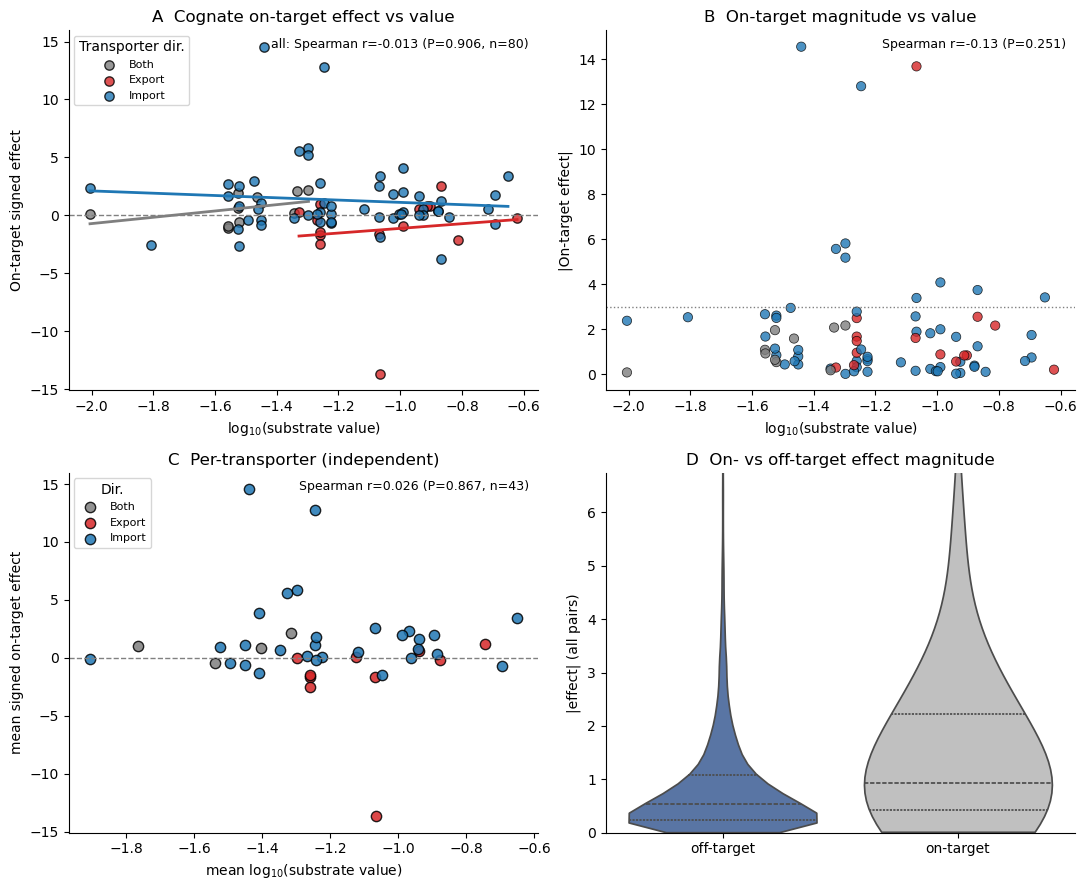

In [5]:
fig,axes=plt.subplots(2,2,figsize=(11,9)); axes=axes.ravel()
pal={'Import':'#1f77b4','Export':'#d62728','Both':'#7f7f7f'}

# A signed on-target effect vs value, by direction
ax=axes[0]
for dn,g in cp.groupby('dir'):
    ax.scatter(g.logv,g['Rel. distance'],color=pal.get(dn,'k'),edgecolor='k',s=45,alpha=.8,label=dn)
    gg=g[['logv','Rel. distance']].dropna()
    if len(gg)>=8:
        b=np.polyfit(gg.logv,gg['Rel. distance'],1); xs=np.linspace(gg.logv.min(),gg.logv.max(),50)
        ax.plot(xs,np.polyval(b,xs),color=pal.get(dn,'k'),lw=2)
ax.axhline(0,ls='--',c='grey',lw=1); ax.legend(title='Transporter dir.',fontsize=8)
s0=sp(cp.logv,cp['Rel. distance'])
ax.text(.98,.98,f"all: Spearman r={s0['r']} (P={s0['p']}, n={s0['n']})",transform=ax.transAxes,va='top',ha='right',fontsize=9)
ax.set(xlabel='log$_{10}$(substrate value)',ylabel='On-target signed effect',title='A  Cognate on-target effect vs value')

# B |on-target effect| vs value
ax=axes[1]
sns.scatterplot(data=cp,x='logv',y='|eff|',hue='dir',palette=pal,edgecolor='k',s=45,alpha=.8,ax=ax,legend=False)
sb=sp(cp.logv,cp['|eff|'])
ax.axhline(min_effect,ls=':',c='grey',lw=1)
ax.text(.98,.98,f"Spearman r={sb['r']} (P={sb['p']})",transform=ax.transAxes,va='top',ha='right',fontsize=9)
ax.set(xlabel='log$_{10}$(substrate value)',ylabel='|On-target effect|',title='B  On-target magnitude vs value')

# C per-transporter aggregate
ax=axes[2]
for dn,g in agg.groupby('dir'):
    ax.scatter(g.mean_logv,g.mean_signed,color=pal.get(dn,'k'),edgecolor='k',s=55,alpha=.85,label=dn)
ax.axhline(0,ls='--',c='grey',lw=1)
sc=sp(agg.mean_logv,agg.mean_signed)
ax.text(.98,.98,f"Spearman r={sc['r']} (P={sc['p']}, n={sc['n']})",transform=ax.transAxes,va='top',ha='right',fontsize=9)
ax.set(xlabel='mean log$_{10}$(substrate value)',ylabel='mean signed on-target effect',title='C  Per-transporter (independent)')
ax.legend(title='Dir.',fontsize=8)

# D on- vs off-target |effect| (validation)
ax=axes[3]
d=pd.DataFrame({'|effect|':dis_mz['Rel. distance'].abs(),
               'group':np.where(dis_mz.ontarget,'on-target','off-target')})
sns.violinplot(data=d,x='group',y='|effect|',ax=ax,cut=0,inner='quartile',palette=['#4c72b0','#c0c0c0'])
ax.set_ylim(0,d['|effect|'].quantile(.995))
ax.set(xlabel='',ylabel='|effect| (all pairs)',title='D  On- vs off-target effect magnitude')

sns.despine(); plt.tight_layout()
figure_folder.mkdir(parents=True,exist_ok=True)
out=figure_folder/f'figure_5_cognate_substrate_value_vs_effect_{norm}_norm_lam_{lam}'
plt.savefig(f'{out}.pdf',dpi=300,bbox_inches='tight'); plt.savefig(f'{out}.png',dpi=150,bbox_inches='tight')
print('saved',out)

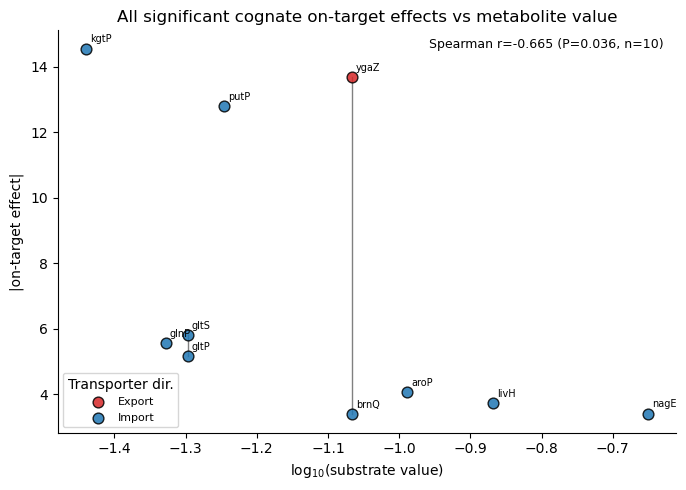

In [8]:

# all significant cognate pairs, |effect| vs substrate value
# metabolites with multiple significant transporters appear as multiple dots at the same x
sig = cp[cp.sig].dropna(subset=['logv']).copy()

fig, ax = plt.subplots(figsize=(7, 5))
for dn, g in sig.groupby('dir'):
    ax.scatter(g.logv, g['|eff|'], color=pal.get(dn, 'k'),
               edgecolor='k', s=60, alpha=.85, label=dn, zorder=3)

# connect dots that share the same metabolite (same x) with a vertical line
for met, g in sig.groupby('Metabolite'):
    if len(g) > 1:
        ax.plot([g.logv.iloc[0]] * len(g), g['|eff|'].values,
                color='grey', lw=1, zorder=2)

# label each point with strain name
for _, row in sig.iterrows():
    ax.annotate(row.Strain, (row.logv, row['|eff|']),
                fontsize=7, ha='left', va='bottom', xytext=(3, 3),
                textcoords='offset points')

sx = sp(sig.logv, sig['|eff|'])
ax.text(.98, .98,
        f"Spearman r={sx['r']} (P={sx['p']}, n={sx['n']})",
        transform=ax.transAxes, va='top', ha='right', fontsize=9)
ax.set(xlabel='log$_{10}$(substrate value)',
       ylabel='|on-target effect|',
       title='All significant cognate on-target effects vs metabolite value')
ax.legend(title='Transporter dir.', fontsize=8)
sns.despine(); plt.tight_layout(); plt.show()


In [7]:
print(f"All {cp.sig.sum()} significant cognate pairs (|eff|>{min_effect}, p<{max_pval}):\n")
print(cp[cp.sig][['Strain','Metabolite','Rel. distance','|eff|','p-value rel','logv','dir']]
      .sort_values('|eff|', ascending=False).to_string(index=False))


All 10 significant cognate pairs (|eff|>3, p<0.005):

Strain             Metabolite  Rel. distance     |eff|  p-value rel      logv    dir
  kgtP           Oxoglutarate      14.557728 14.557728          0.0 -1.440538 Import
  ygaZ                 Valine     -13.683664 13.683664          0.0 -1.066944 Export
  putP                Proline      12.802219 12.802219          0.0 -1.246414 Import
  gltS              Glutamate       5.813300  5.813300          0.0 -1.297281 Import
  glnP              Glutamine       5.570460  5.570460          0.0 -1.328000 Import
  gltP              Glutamate       5.182146  5.182146          0.0 -1.297281 Import
  aroP          Phenylalanine       4.080977  4.080977          0.0 -0.989421 Import
  livH           (Iso)Leucine      -3.743089  3.743089          0.0 -0.868875 Import
  nagE N-Acetyl-D-glucosamine       3.415352  3.415352          0.0 -0.650599 Import
  brnQ                 Valine       3.390908  3.390908          0.0 -1.066944 Import


## Summary

Restricting each transporter to its **annotated cognate substrate** removes the off-target noise:
panel D confirms on-target effects are genuinely larger than off-target ones (median |effect|
0.94 vs 0.55, Mann-Whitney P≈1e-5), so the matching captures real biology.

On this cleanest test, **substrate value does not predict the on-target effect**:
- All 80 cognate pairs: signed effect vs value Spearman r=−0.01 (P=0.9); |effect| vs value r=−0.13 (P=0.25).
- **Per-transporter aggregate (pseudoreplication-free, n=43): r=0.03 (P=0.87)** — the test to trust.
- The only "significant" slice (10 significant pairs, r=−0.74) rests on N=10 and is not robust.

Conclusion: even after eliminating off-target dilution and detection-breadth effects, the
value↔transporter-effect link is absent. Combined with 2J, this is a defensible, mechanism-based
negative result — transporter-level control of release appears **decoupled from metabolite value**,
which the bulk release rate (Figs 1–2) tracks strongly. That decoupling is itself a clean finding:
value governs the thermodynamic/steady-state release, but which transporters gate a metabolite is
set by substrate identity and physiology, not by its biosynthetic cost.